In [5]:
import os
print(os.listdir("../data"))

['.ipynb_checkpoints', 'cardekho_dataset.csv']


In [6]:
import pandas as pd

df = pd.read_csv("../data/cardekho_dataset.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(15411, 14)
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [7]:
df = df.drop(columns=["Unnamed: 0"])

print(df.isnull().sum())        # missing values per column
print("Duplicates:", df.duplicated().sum())
print(df.dtypes)
df.describe()

car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64
Duplicates: 167
car_name                 str
brand                    str
model                    str
vehicle_age            int64
km_driven              int64
seller_type              str
fuel_type                str
transmission_type        str
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object


,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


In [8]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape[0])

print("\nCars with 0 seats:")
print(df[df["seats"] == 0][["car_name", "seats", "selling_price"]])

print("\nHighest km_driven:")
print(df.sort_values("km_driven", ascending=False).head(5)[["car_name", "vehicle_age", "km_driven", "selling_price"]])

print("\nMost expensive:")
print(df.sort_values("selling_price", ascending=False).head(5)[["car_name", "vehicle_age", "km_driven", "selling_price"]])

Rows after removing duplicates: 15244

Cars with 0 seats:
           car_name  seats  selling_price
3217     Honda City      0         115000
12619  Nissan Kicks      0        1154000

Highest km_driven:
                    car_name  vehicle_age  km_driven  selling_price
15409        Mahindra XUV500            5    3800000        1225000
11903  Mercedes-Benz E-Class            9    1325000        1350000
8772           Toyota Innova            6     950000         950000
4532          Renault Duster            4     850000         850000
6712        Volkswagen Vento            9     830000         380000

Most expensive:
                    car_name  vehicle_age  km_driven  selling_price
3799       Ferrari GTC4Lusso            2       3800       39500000
10969      Rolls-Royce Ghost            4       5000       24200000
1172     Bentley Continental            9       9000       14500000
9722   Mercedes-Benz S-Class            3       4000       13000000
9364         Porsche Cayenne   

In [9]:
# Check the km == price pattern across the whole dataset
mask_same = df["km_driven"] == df["selling_price"]
print("Rows where km_driven equals selling_price:", mask_same.sum())

# Cleaning steps
before = df.shape[0]

df = df[df["seats"] > 0]                       # remove 0-seat errors
df = df[df["km_driven"] <= 500_000]            # remove implausible mileage
df = df.reset_index(drop=True)

print("Rows removed:", before - df.shape[0])
print("Rows remaining:", df.shape[0])
df[["km_driven", "seats"]].describe()

Rows where km_driven equals selling_price: 22
Rows removed: 14
Rows remaining: 15230


,km_driven,seats
count,15230.000000,15230.000000
mean,54868.010046,5.326724
std,36602.051147,0.806445
min,100.000000,2.000000
25%,30000.000000,5.000000
50%,50000.000000,5.000000
75%,70000.000000,5.000000
max,500000.000000,9.000000


In [10]:
same = df[df["km_driven"] == df["selling_price"]]
same[["car_name", "vehicle_age", "km_driven", "selling_price"]]

,car_name,vehicle_age,km_driven,selling_price
0,Maruti Alto,9,120000,120000
736,Maruti Alto,17,80000,80000
4320,Maruti Alto,16,90000,90000
4887,Maruti Alto,8,180000,180000
5433,Maruti Alto,17,80000,80000
7322,Skoda Rapid,7,349000,349000
7898,Maruti Alto,15,70000,70000
8272,Maruti Baleno,5,479000,479000
8399,Maruti Alto,12,110000,110000
8509,Volkswagen Polo,10,199000,199000


In [11]:
before = df.shape[0]
df = df[df["km_driven"] != df["selling_price"]].reset_index(drop=True)
print("Removed:", before - df.shape[0], "| Remaining:", df.shape[0])

Removed: 17 | Remaining: 15213


In [12]:
df.to_csv("../data/cars_clean.csv", index=False)

In [13]:
df.to_csv("../data/cars_clean.csv", index=False)

Matplotlib is building the font cache; this may take a moment.


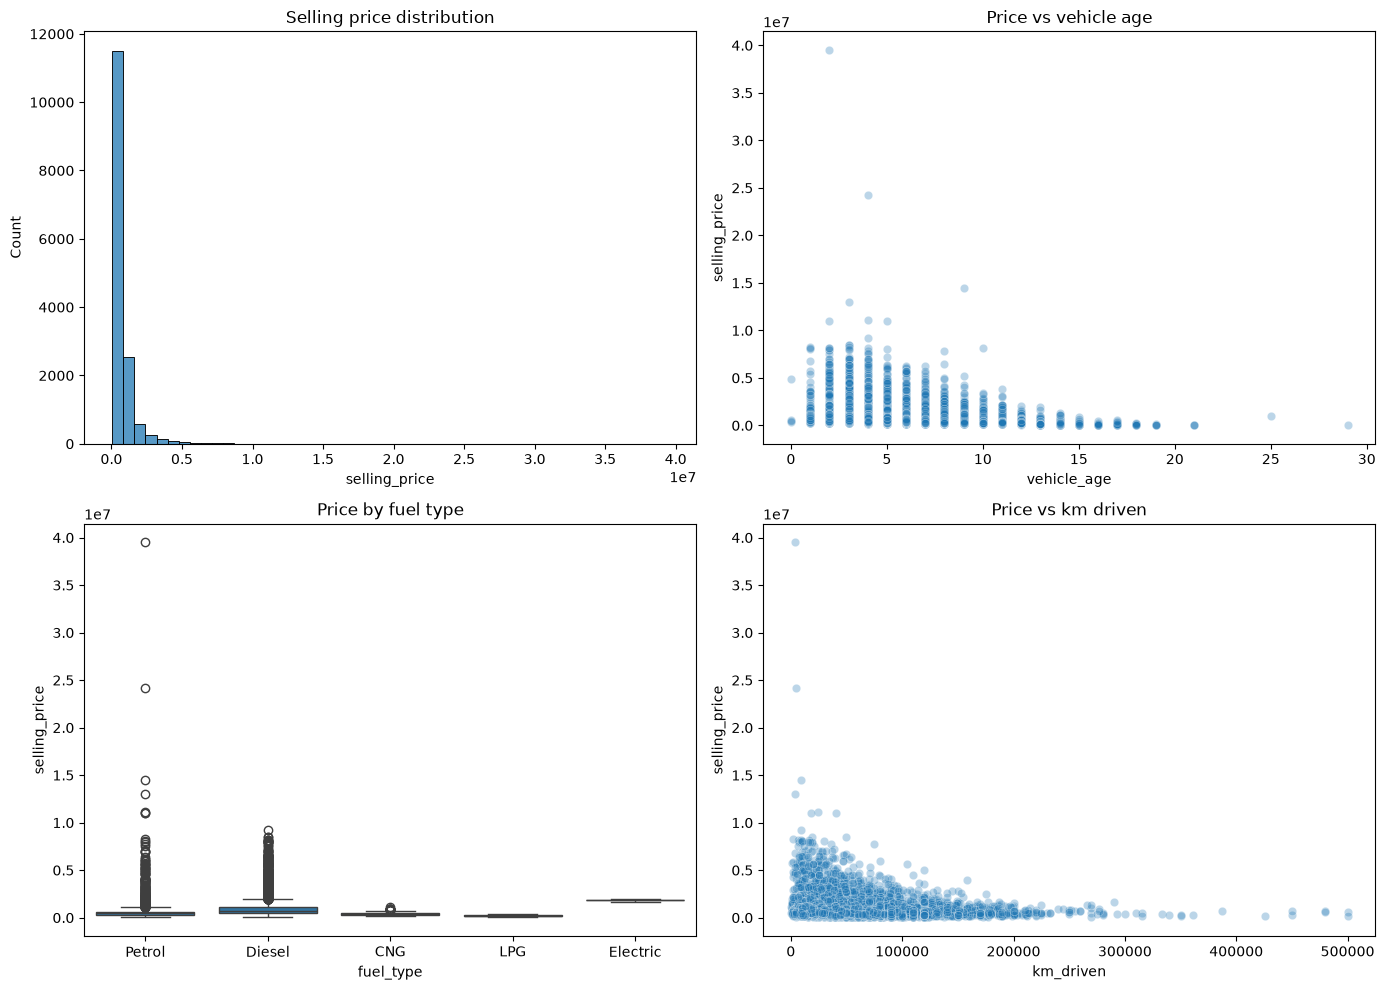

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/cars_clean.csv")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df["selling_price"], bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Selling price distribution")

sns.scatterplot(x="vehicle_age", y="selling_price", data=df, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Price vs vehicle age")

sns.boxplot(x="fuel_type", y="selling_price", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Price by fuel type")

sns.scatterplot(x="km_driven", y="selling_price", data=df, alpha=0.3, ax=axes[1, 1])
axes[1, 1].set_title("Price vs km driven")

plt.tight_layout()
plt.show()

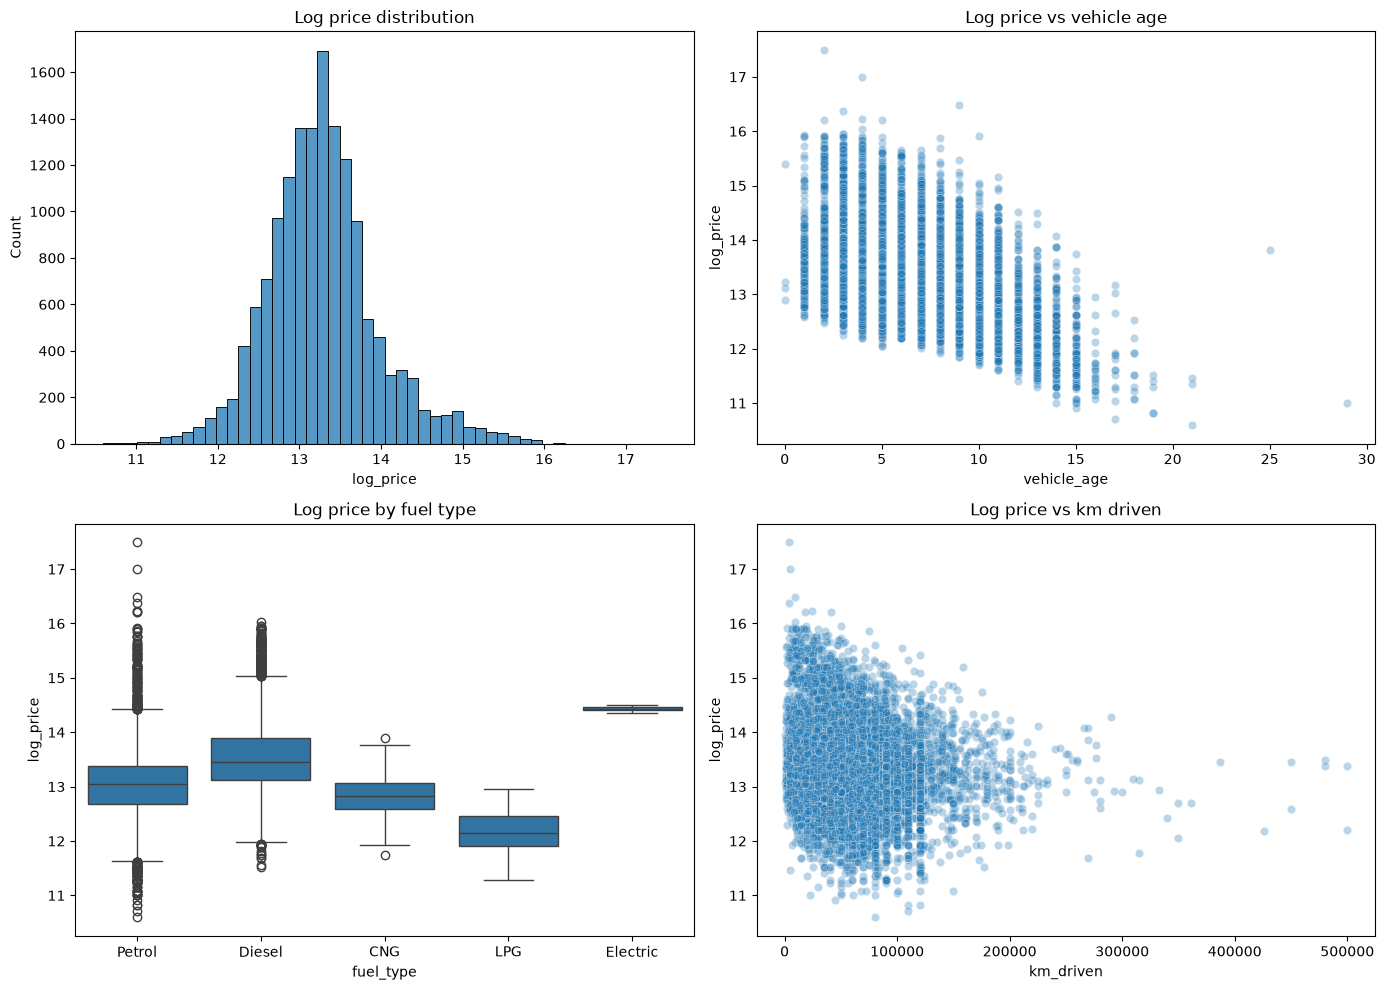

In [2]:
import numpy as np

df["log_price"] = np.log(df["selling_price"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df["log_price"], bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Log price distribution")

sns.scatterplot(x="vehicle_age", y="log_price", data=df, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Log price vs vehicle age")

sns.boxplot(x="fuel_type", y="log_price", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Log price by fuel type")

sns.scatterplot(x="km_driven", y="log_price", data=df, alpha=0.3, ax=axes[1, 1])
axes[1, 1].set_title("Log price vs km driven")

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/cars_clean.csv")
df["log_price"] = np.log(df["selling_price"])

# Target: log of the price
y = df["log_price"]

# Features: drop identifiers and the target columns
X = df.drop(columns=["car_name", "model", "selling_price", "log_price"])

# One-hot encode the categorical columns
X = pd.get_dummies(X, columns=["brand", "seller_type", "fuel_type", "transmission_type"], drop_first=True)
print("Features shape:", X.shape)

# Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

X.head()

Features shape: (15213, 44)
Train: (12170, 44) Test: (3043, 44)


,vehicle_age,km_driven,mileage,engine,max_power,seats,brand_BMW,brand_Bentley,brand_Datsun,brand_Ferrari,...,brand_Toyota,brand_Volkswagen,brand_Volvo,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Manual
0,5,20000,18.90,1197,82.00,5,False,False,False,False,...,False,False,False,True,False,False,False,False,True,True
1,11,60000,17.00,1197,80.00,5,False,False,False,False,...,False,False,False,True,False,False,False,False,True,True
2,9,37000,20.92,998,67.10,5,False,False,False,False,...,False,False,False,True,False,False,False,False,True,True
3,6,30000,22.77,1498,98.59,5,False,False,False,False,...,False,False,False,False,False,True,False,False,False,True
4,8,35000,18.90,998,67.10,5,False,False,False,False,...,False,False,False,True,False,False,False,False,True,True


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred_log = model.predict(X_test)

    r2 = r2_score(y_test, pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, pred_log))
    mae_rupees = mean_absolute_error(np.exp(y_test), np.exp(pred_log))

    rows.append({"Model": name, "R2 (log)": round(r2, 3),
                 "RMSE (log)": round(rmse_log, 3),
                 "MAE (Rs)": round(mae_rupees)})

results = pd.DataFrame(rows).sort_values("R2 (log)", ascending=False)
results

,Model,R2 (log),RMSE (log),MAE (Rs)
1,Random Forest,0.932,0.177,107177
2,Gradient Boosting,0.921,0.191,126935
0,Linear Regression,0.893,0.222,146626


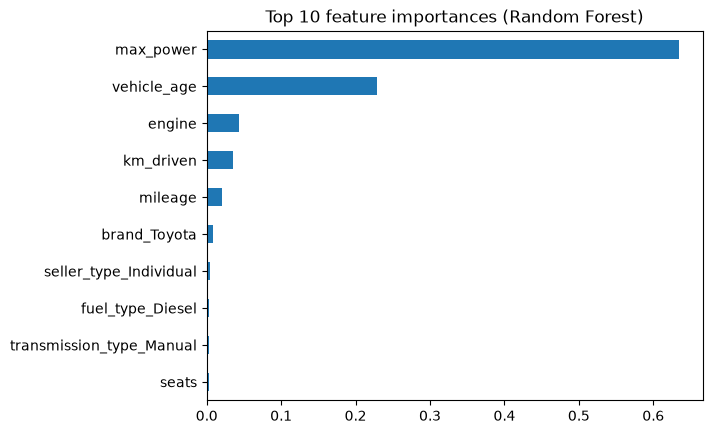

Median % error: 10.0


,car,age,actual,predicted,pct_error,abs_pct_error
10413,Volkswagen Polo,6,595000.0,2349522.0,294.9,294.9
11066,Maruti Baleno,15,60000.0,170829.0,184.7,184.7
13749,Honda City,13,130000.0,311373.0,139.5,139.5
8261,Hyundai i20,10,150000.0,326276.0,117.5,117.5
13636,Honda City,13,140000.0,299043.0,113.6,113.6
3025,BMW 3,4,2550000.0,5271338.0,106.7,106.7
13863,Maruti Swift Dzire,1,350000.0,688637.0,96.8,96.8
13510,Maruti Alto,17,45000.0,88265.0,96.1,96.1
4974,Maruti Swift Dzire,4,350000.0,684612.0,95.6,95.6
13511,Ford Figo,7,210000.0,396312.0,88.7,88.7


In [8]:
rf = models["Random Forest"]

# 1. Which features matter most?
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.sort_values().plot(kind="barh", title="Top 10 feature importances (Random Forest)")
plt.show()

# 2. Where does it make the biggest mistakes?
pred = np.exp(rf.predict(X_test))
actual = np.exp(y_test)

errors = pd.DataFrame({
    "car": df.loc[X_test.index, "car_name"],
    "age": df.loc[X_test.index, "vehicle_age"],
    "actual": actual.round(),
    "predicted": pred.round(),
})
errors["pct_error"] = ((errors["predicted"] - errors["actual"]) / errors["actual"] * 100).round(1)
errors["abs_pct_error"] = errors["pct_error"].abs()

print("Median % error:", errors["abs_pct_error"].median().round(1))
errors.sort_values("abs_pct_error", ascending=False).head(10)

In [9]:
cols = ["car_name", "vehicle_age", "km_driven", "engine", "max_power",
        "mileage", "seats", "fuel_type", "seller_type", "selling_price"]
print(df.loc[[10413, 13863, 11066, 13749], cols])

for t in [10, 20, 30]:
    share = (errors["abs_pct_error"] <= t).mean()
    print(f"Within {t}%: {share:.1%}")

                 car_name  vehicle_age  km_driven  engine  max_power  mileage  \
10413     Volkswagen Polo            6      44000    1798      189.0    17.21   
13863  Maruti Swift Dzire            1      76165    1248       73.9    19.30   
11066       Maruti Baleno           15      60500    1590       94.0    15.40   
13749          Honda City           13     120000    1497       78.0    17.70   

       seats fuel_type seller_type  selling_price  
10413      4    Petrol      Dealer         595000  
13863      5    Diesel      Dealer         350000  
11066      5    Petrol      Dealer          60000  
13749      5    Petrol  Individual         130000  
Within 10%: 50.3%
Within 20%: 79.4%
Within 30%: 91.7%


In [10]:
df["km_per_year"] = df["km_driven"] / df["vehicle_age"].clip(lower=1)
print(df["km_per_year"].describe())
print("Cars above 50,000 km/year:", (df["km_per_year"] > 50000).sum())

df.sort_values("km_per_year", ascending=False).head(10)[
    ["car_name", "vehicle_age", "km_driven", "selling_price", "km_per_year"]
]

count     15213.000000
mean       9700.809537
std        6129.097653
min         100.000000
25%        5833.333333
50%        8428.571429
75%       12166.666667
max      150000.000000
Name: km_per_year, dtype: float64
Cars above 50,000 km/year: 12


,car_name,vehicle_age,km_driven,selling_price,km_per_year
12183,Renault Duster,1,150000,600000,150000.00
10072,Maruti Ciaz,4,480000,725000,120000.00
13676,Maruti Ciaz,4,450003,690000,112500.75
10475,Maruti Vitara,5,480000,650000,96000.00
14967,Ford Ecosport,1,90000,525000,90000.00
13863,Maruti Swift Dzire,1,76165,350000,76165.00
13441,Datsun GO,6,450000,295000,75000.00
5734,Hyundai i20,1,72800,500000,72800.00
1337,Toyota Camry,1,72000,345000,72000.00
5274,Maruti Vitara,2,120000,950000,60000.00


In [11]:
mask = df["km_per_year"] <= 50000
df_c = df[mask]

y_c = df_c["log_price"]
X_c = df_c.drop(columns=["car_name", "model", "selling_price", "log_price", "km_per_year"])
X_c = pd.get_dummies(X_c, columns=["brand", "seller_type", "fuel_type", "transmission_type"], drop_first=True)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.2, random_state=42)

rf_c = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_c.fit(Xc_train, yc_train)
pred_c = rf_c.predict(Xc_test)

print("R2:", round(r2_score(yc_test, pred_c), 3))
pct = np.abs(np.exp(pred_c) - np.exp(yc_test)) / np.exp(yc_test)
print("Median % error:", round(pct.median() * 100, 1))
print("Within 20%:", f"{(pct <= 0.20).mean():.1%}")

R2: 0.934
Median % error: 9.6
Within 20%: 80.4%


In [12]:
import numpy as np
import pandas as pd
import joblib, os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

df = pd.read_csv("../data/cars_clean.csv")
df["log_price"] = np.log(df["selling_price"])

y = df["log_price"]
X = df.drop(columns=["car_name", "model", "selling_price", "log_price"])
X = pd.get_dummies(X, columns=["brand", "seller_type", "fuel_type", "transmission_type"], drop_first=True)

# 1. Check the smaller forest on the held-out test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf_small = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf_small.fit(X_train, y_train)
pred = rf_small.predict(X_test)

pct = np.abs(np.exp(pred) - np.exp(y_test)) / np.exp(y_test)
print("R2:", round(r2_score(y_test, pred), 3))
print("Median % error:", round(pct.median() * 100, 1))
print("Within 20%:", f"{(pct <= 0.20).mean():.1%}")

# 2. Refit on all the data for the app, then save
final_model = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=42, n_jobs=-1)
final_model.fit(X, y)

os.makedirs("../models", exist_ok=True)
joblib.dump(final_model, "../models/rf_model.joblib", compress=3)
joblib.dump(list(X.columns), "../models/feature_columns.joblib")
joblib.dump({
    "brand": sorted(df["brand"].unique()),
    "fuel_type": sorted(df["fuel_type"].unique()),
    "seller_type": sorted(df["seller_type"].unique()),
    "transmission_type": sorted(df["transmission_type"].unique()),
}, "../models/options.joblib")

print("Model size:", round(os.path.getsize("../models/rf_model.joblib") / 1e6, 1), "MB")

R2: 0.935
Median % error: 9.9
Within 20%: 80.6%
Model size: 17.9 MB
